# Test Code Execution with Energy Profiling

In [1]:
# Import modules
import lassi.code_manager
import lassi.llm_methods
from lassi.get_power import report_gpu_memory
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.code_manager
%aimport lassi.llm_methods
%aimport lassi.get_power
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary

prompts = PromptDictionary()

In [18]:
report_gpu_memory()


----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 49.78 W, P0



In [19]:
!nvidia-smi

Tue Apr  1 01:46:46 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.05              Driver Version: 560.35.05      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          Off |   00000000:24:00.0 Off |                    0 |
| N/A   48C    P0             49W /  300W |       1MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [2]:
# Code to test
folder = "test_codes/segment-reduce/"
code_filename = "main.cu"
exe_input_parameters = ["16384", "100"]

with open(folder + "/" + code_filename, 'r') as file:
    refactored_code = file.read()
file.close()

# Parameters
power_measure = True

source_language = "CUDA"
target_language = "CUDA"
build_script = False
code_compiler = "nvcc"
code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
# -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s  # -arch=sm_60 for P100

In [3]:
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + '/' + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'test_codes/segment-reduce//main.cu', '-o', 'test_codes/segment-reduce//main']

Compilation of code successful!



Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 49.78 W, P0



Waiting for the system to settle down for 0 seconds...: 0it [00:00, ?it/s]

Working directory: test_codes/segment-reduce
Execute command: ['./main', '16384', '100']



num_elements = 268435456
num_segments = 16777216 segment_size = 16 Throughput = 131.490753 (G/s)
num_segments = 8388608 segment_size = 32 Throughput = 135.216324 (G/s)
num_segments = 4194304 segment_size = 64 Throughput = 145.456299 (G/s)
num_segments = 2097152 segment_size = 128 Throughput = 148.613449 (G/s)
num_segments = 1048576 segment_size = 256 Throughput = 149.654572 (G/s)
num_segments = 524288 segment_size = 512 Throughput = 147.124420 (G/s)
num_segments = 262144 segment_size = 1024 Throughput = 150.035461 (G/s)
num_segments = 131072 segment_size = 2048 Throughput = 150.728958 (G/s)
num_segments = 65536 segment_size = 4096 Throughput = 150.906464 (G/s)
num_segments = 32768 segment_size = 8192 Throughput = 151.182190 (G/s)
num_segments = 16384 segment_size = 16384 Throughput = 168.019974 (G/s)
GPU power data has been written to CUDA_CUDA_gpu_net_power_results.csv


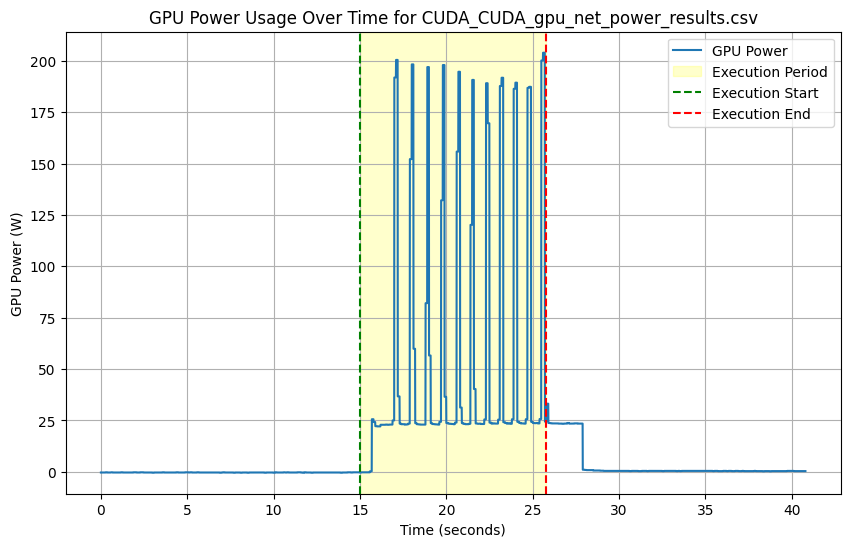

Start time: 15.001 -- End time: 25.787
Total GPU energy consumption for CUDA_CUDA_gpu_net_power_results.csv:
  0.000165 kWh
  0.1648 Wh
  593.31 J
Average GPU power: 55.04 W
Total Energy During Exe Runtime:   593.31 J
Code execution duration: 10.79 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.47 W, P0



In [4]:
execute_result, exe_output, total_energy_joules, ave_power, duration, metrics_results_string = lassi.code_manager.execute_code(
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=0
)

In [ ]:
# Measure system idle power
"""
print("Measure system idle power...")
idle_energy_joules, idle_ave_power = lassi.get_power.idlepower(duration)
actual_energy = total_energy_joules - idle_energy_joules
actual_ave_power = ave_power - idle_ave_power
print(color.BOLD + color.BLUE + "\nActual measured values during runtime for " + color.END + str(code_filename))
print("Average GPU power: " + color.BOLD + f"{actual_ave_power:.2f} W" + color.END)
print("Total Energy During Exe Runtime: " + color.BOLD + f"{actual_energy:.2f} J" + color.END)
"""

# Code Validation - LLM-as-a-Judge

In [5]:
# Run source code
# Call llm-as-a-judge method
# Source Code to test
folder = "test_codes/pathfinder/"
code_filename = "pathfinder-cuda_main.cu"
with open(folder + "/" + code_filename, 'r') as file:
    source_code = file.read()
file.close()

In [6]:
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + '/' + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'test_codes/pathfinder//pathfinder-cuda_main.cu', '-o', 'test_codes/pathfinder//pathfinder-cuda_main']

Compilation of code successful!



Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.57 W, P0



Waiting for the system to settle down for 0 seconds...: 0it [00:00, ?it/s]

Working directory: test_codes/pathfinder
Execute command: ['./pathfinder-cuda_main', '100000', '10000', '2500']



Total kernel execution time: 13.591697 (s)
Device offloading time = 14.173658 (s)
GPU power data has been written to CUDA_CUDA_gpu_net_power_results.csv


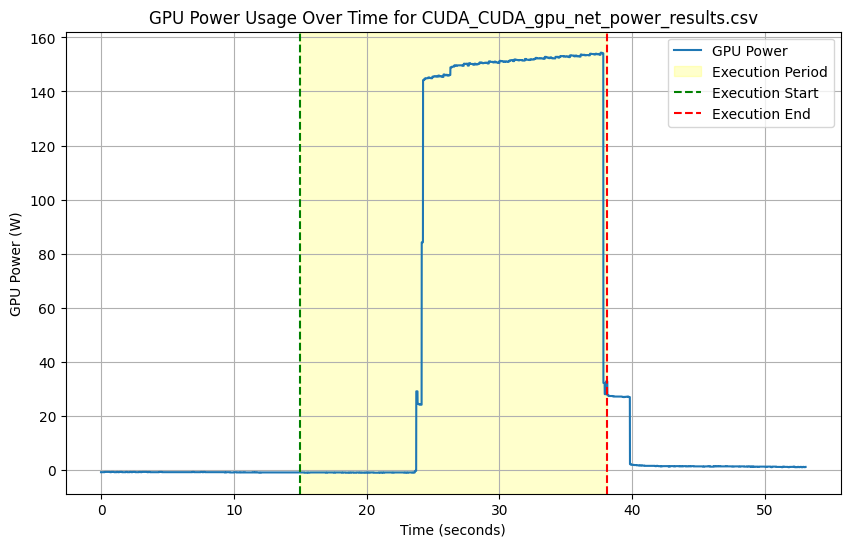

Start time: 15.001 -- End time: 38.062
Total GPU energy consumption for CUDA_CUDA_gpu_net_power_results.csv:
  0.000576 kWh
  0.5761 Wh
  2073.86 J
Average GPU power: 89.93 W
Total Energy During Exe Runtime:   2073.86 J
Code execution duration: 23.06 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 52.82 W, P0



In [7]:
execute_result_source, exe_output_source, total_energy_joules_source, ave_power_source, duration_source, metrics_results_string_source = lassi.code_manager.execute_code(
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=0
)

In [ ]:
# Save source code results into a local JSON file for quick loading

In [9]:
llm_source = "argo"
model_judge = "gpto3mini"
num_ctx = 20000
general_system_prompt = prompts.get_system_prompt("general_system_ee")
input_content_llmjudge_dict = {
    "source_code": source_code,
    "source_stdout": exe_output_source,
    "source_metrics": metrics_results_string_source,
    "refactored_code": refactored_code,
    "refactored_stdout": exe_output,
    "refactored_metrics": metrics_results_string,
} 
display_response = True
verifyprompt = False

# Call LLM-as-a-judge to review SOURCE CODE and REFACTORED CODE to evaluate if likely valid
valid_code_flag = lassi.llm_methods.llm_judge(
    llm_source,
    model_judge,
    num_ctx,
    general_system_prompt,
    input_content_llmjudge_dict,
    display_response,
    verifyprompt
)
print(f"\nResult: {valid_code_flag}")



--> ... prompt LLM to judge the validity of the refactored code.





----- LLM RESPONSE: code validation judge -----



The refactored code retains the core algorithm exactly—the Jacobi relaxation kernel, the halo data handling, the error reduction via warp shuffles, and the data swap kernel are all kept functionally identical. The changes are mainly refactorings aimed at energy efficiency while preserving the algorithm:

1. The refactored code combines nested conditionals (both in the jacobi_step and swap_data kernels) which reduces branch divergence but does not alter the logic.
2. Memory allocation for the host arrays now uses cudaMallocHost (pinned memory) instead of aligned_alloc. This change is beneficial for throughput on data transfers and does not change the outcomes.
3. The cudaMemset call in the loop now properly uses sizeof(float) for clarity, though the original use of “4” didn’t change functionality.
4. Comments indicate the intent of standard math functions remains the same.
5. The standard output (layout and values) remains nearly identical—with only small numerical differences in timings and energy, which are acceptable indicators of improved energy efficiency.

Since functionality, kernel logic, and the printed output are preserved with only eligible minor numerical differences, the refactored code is functionally equivalent to the source code.

VALID



----- END LLM RESPONSE -----


Result: VALID
